Hay chon file CSV de phan tich:


Saving gia_nha_sample.csv to gia_nha_sample.csv

========== TONG QUAN DU LIEU ==========
So dong: 50
So cot: 4


,Dien_tich_m2,So_phong_ngu,Khoang_cach_trung_tam_km,Gia_ban_trieu_VND
0,70.0,3,11.2,2759.1
1,116.1,2,11.8,3766.2
2,98.6,2,2.0,3229.7
3,87.9,4,6.0,3458.8
4,52.5,2,2.6,2164.7


,count,mean,std,min,25%,50%,75%,max
Dien_tich_m2,50.0,75.674,23.111529,41.6,54.725,74.90,91.975,117.6
So_phong_ngu,50.0,2.560,1.214874,1.0,1.000,3.00,4.000,4.0
Khoang_cach_trung_tam_km,50.0,7.832,4.058975,1.4,4.275,8.00,11.675,14.0
Gia_ban_trieu_VND,50.0,2787.760,747.641533,1702.5,2181.700,2708.55,3357.325,4206.6



Gia tri thieu theo cot:


,So gia tri thieu
Dien_tich_m2,0
So_phong_ngu,0
Khoang_cach_trung_tam_km,0
Gia_ban_trieu_VND,0



========== BIEN MUC TIEU ==========
Chuong trinh tu chon Y = Gia_ban_trieu_VND
Luu y: Hay kiem tra Y co dung muc tieu ban muon du doan.
Cac bien X: ['Dien_tich_m2', 'So_phong_ngu', 'Khoang_cach_trung_tam_km']
So dong duoc su dung: 50


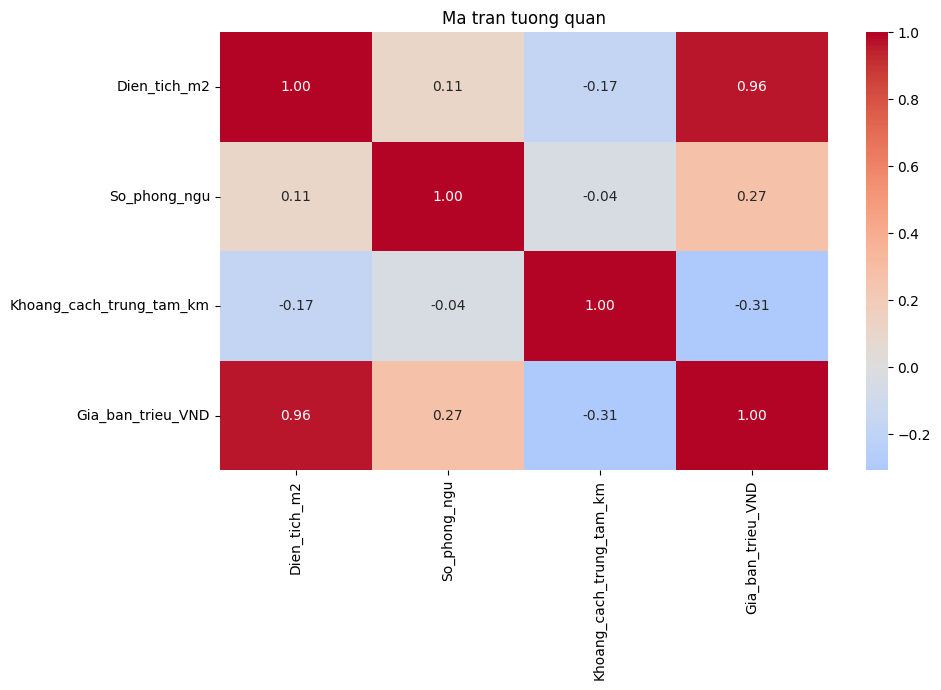


========== SO SANH MO HINH ==========


,Mo hinh,R2,MAE,MSE,RMSE
0,Hoi quy tuyen tinh,0.956901,116.163560,20592.894695,143.502246
1,Ridge,0.956075,113.957753,20987.600821,144.870980
2,Random Forest,0.849681,210.278450,71823.102821,267.998326


Mo hinh duoc chon: Hoi quy tuyen tinh


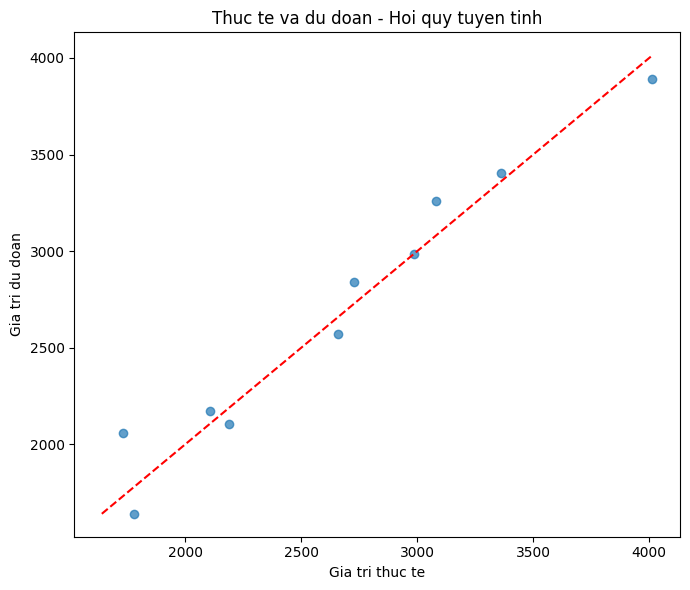

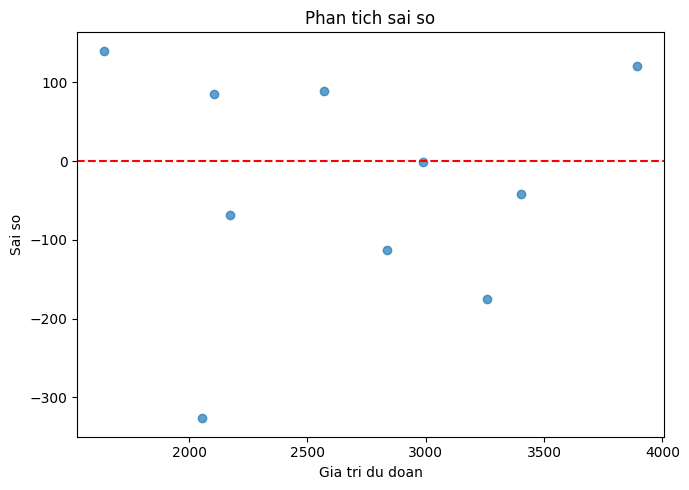

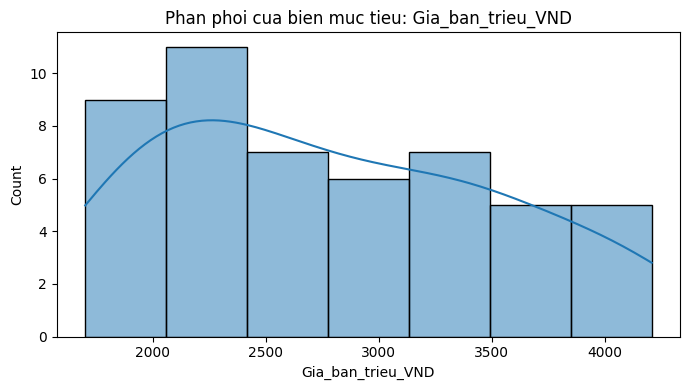


========== NHAN XET ==========
Bien can du doan: Gia_ban_trieu_VND
Mo hinh tot nhat trong cac mo hinh da thu: Hoi quy tuyen tinh
R2   = 0.9569
MAE  = 116.1636
MSE  = 20592.8947
RMSE = 143.5022
R2 tuong doi cao tren tap kiem tra.
Luu y: Ket qua phu thuoc chat luong va kich thuoc du lieu.
Tuong quan khong dong nghia voi quan he nhan qua.

DA HOAN THANH! Dang tai cac file ket qua...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:


!pip -q install chardet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import chardet

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error,
    mean_squared_error
)


print("Hay chon file CSV de phan tich:")
uploaded = files.upload()

filename = next(iter(uploaded))
raw = uploaded[filename]

encoding = chardet.detect(raw[:100000]).get("encoding") or "utf-8"
content = raw.decode(encoding, errors="replace")

try:
    import csv
    delimiter = csv.Sniffer().sniff(
        content[:10000], delimiters=",;\t|"
    ).delimiter
except:
    delimiter = ","

df = pd.read_csv(io.StringIO(content), sep=delimiter)
df.columns = df.columns.astype(str).str.strip()
df = df.dropna(how="all").dropna(axis=1, how="all")


for col in df.select_dtypes(include="object").columns:
    s = df[col].astype(str).str.strip()
    converted = pd.to_numeric(
        s.str.replace(",", ".", regex=False),
        errors="coerce"
    )
    valid = s.isin(["", "nan", "None"]) == False
    if valid.sum() and converted[valid].notna().mean() >= 0.85:
        df[col] = converted

print("\n========== TONG QUAN DU LIEU ==========")
print("So dong:", df.shape[0])
print("So cot:", df.shape[1])
display(df.head())
display(df.describe(include="all").T)

print("\nGia tri thieu theo cot:")
display(df.isnull().sum().to_frame("So gia tri thieu"))


numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if len(numeric_cols) < 2:
    raise ValueError(
        "Can it nhat 2 cot so: mot cot muc tieu Y "
        "va mot cot dau vao X."
    )


keywords = [
    "target", "label", "price", "gia", "score", "diem",
    "sales", "revenue", "doanh thu", "salary", "luong",
    "profit", "total", "tong", "outcome", "ket qua"
]

def target_score(col):
    name = str(col).lower()
    score = sum(k in name for k in keywords) * 3
    if name.strip() in ["y", "target", "label", "outcome"]:
        score += 10
    return score

eligible = [
    c for c in numeric_cols
    if df[c].notna().sum() >= max(5, int(len(df) * 0.5))
    and df[c].nunique() > 1
]

if len(eligible) < 2:
    raise ValueError(
        "Khong tim duoc du cot so hop le de hoi quy."
    )


target = max(
    eligible,
    key=lambda c: (target_score(c), df.columns.get_loc(c))
)

print("\n========== BIEN MUC TIEU ==========")
print("Chuong trinh tu chon Y =", target)
print("Luu y: Hay kiem tra Y co dung muc tieu ban muon du doan.")


features = []
for col in df.columns:
    if col == target or df[col].nunique(dropna=True) <= 1:
        continue

    name = str(col).lower()
    unique_ratio = (
        df[col].nunique(dropna=True)
        / max(df[col].notna().sum(), 1)
    )

    if any(k in name for k in ["id", "ma_", "code", "stt"]) and unique_ratio > 0.5:
        continue

    if df[col].notna().sum() >= max(3, int(len(df) * 0.3)):
        features.append(col)

if not features:
    raise ValueError("Khong co cot dau vao phu hop.")


X = df[features].copy()
y = pd.to_numeric(df[target], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

for col in list(X.columns):
    if X[col].dtype == "object":
        if X[col].nunique(dropna=True) > min(100, max(30, len(X) // 2)):
            X.drop(columns=col, inplace=True)

if X.shape[1] == 0 or len(X) < 5:
    raise ValueError("Du lieu sau lam sach khong du de hoi quy.")

print("Cac bien X:", X.columns.tolist())
print("So dong duoc su dung:", len(X))


numeric_data = df.select_dtypes(include=np.number)

if numeric_data.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        numeric_data.corr(),
        annot=True, cmap="coolwarm",
        fmt=".2f", center=0
    )
    plt.title("Ma tran tuong quan")
    plt.tight_layout()
    plt.show()


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2 if len(X) >= 10 else 0.4,
    random_state=42
)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

transformers = []

if num_cols:
    transformers.append((
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        num_cols
    ))

if cat_cols:
    transformers.append((
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        cat_cols
    ))

preprocessor = ColumnTransformer(transformers)


models = {
    "Hoi quy tuyen tinh": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

results = []
trained = {}
predictions = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    try:
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)

        mse = mean_squared_error(y_test, pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, pred) if len(y_test) >= 2 else np.nan
        mae = mean_absolute_error(y_test, pred)

        results.append({
            "Mo hinh": name,
            "R2": r2,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse
        })

        trained[name] = pipe
        predictions[name] = pred

    except Exception as e:
        print("Loi mo hinh", name, ":", e)

if not results:
    raise ValueError("Tat ca mo hinh deu that bai.")

metrics = pd.DataFrame(results)


if metrics["R2"].notna().any():
    best_name = metrics.sort_values(
        ["R2", "RMSE"], ascending=[False, True]
    ).iloc[0]["Mo hinh"]
else:
    best_name = metrics.sort_values("RMSE").iloc[0]["Mo hinh"]

best_model = trained[best_name]
best_pred = predictions[best_name]

print("\n========== SO SANH MO HINH ==========")
display(metrics.sort_values("RMSE"))
print("Mo hinh duoc chon:", best_name)


plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.7)

low = min(y_test.min(), np.min(best_pred))
high = max(y_test.max(), np.max(best_pred))
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Gia tri thuc te")
plt.ylabel("Gia tri du doan")
plt.title("Thuc te va du doan - " + best_name)
plt.tight_layout()
plt.show()


residuals = np.asarray(y_test) - np.asarray(best_pred)

plt.figure(figsize=(7, 5))
plt.scatter(best_pred, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Gia tri du doan")
plt.ylabel("Sai so")
plt.title("Phan tich sai so")
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 4))
sns.histplot(y, kde=True)
plt.title("Phan phoi cua bien muc tieu: " + str(target))
plt.tight_layout()
plt.show()


row = metrics[metrics["Mo hinh"] == best_name].iloc[0]

print("\n========== NHAN XET ==========")
print("Bien can du doan:", target)
print("Mo hinh tot nhat trong cac mo hinh da thu:", best_name)
print(f"R2   = {row['R2']:.4f}")
print(f"MAE  = {row['MAE']:.4f}")
print(f"MSE  = {row['MSE']:.4f}")
print(f"RMSE = {row['RMSE']:.4f}")

if pd.notna(row["R2"]):
    if row["R2"] >= 0.7:
        print("R2 tuong doi cao tren tap kiem tra.")
    elif row["R2"] >= 0.3:
        print("R2 o muc vua phai, co the can them du lieu hoac bien dau vao.")
    elif row["R2"] >= 0:
        print("R2 thap, kha nang du doan con han che.")
    else:
        print("R2 am: mo hinh kem hon viec du doan bang gia tri trung binh.")

print("Luu y: Ket qua phu thuoc chat luong va kich thuoc du lieu.")
print("Tuong quan khong dong nghia voi quan he nhan qua.")


all_X = df.reindex(columns=X.columns).copy()

for col in all_X.columns:
    if col in num_cols:
        all_X[col] = pd.to_numeric(all_X[col], errors="coerce")

all_predictions = best_model.predict(all_X)

output = df.copy()
output["Du_doan_" + str(target)] = all_predictions
output["Sai_so"] = (
    pd.to_numeric(output[target], errors="coerce")
    - output["Du_doan_" + str(target)]
)


test_output = X_test.copy()
test_output["Gia_tri_thuc_te"] = y_test
test_output["Gia_tri_du_doan"] = best_pred
test_output["Sai_so"] = np.asarray(y_test) - np.asarray(best_pred)

metrics.to_csv(
    "so_sanh_mo_hinh.csv", index=False, encoding="utf-8-sig"
)
output.to_csv(
    "du_doan_toan_bo_du_lieu.csv", index=False, encoding="utf-8-sig"
)
test_output.to_csv(
    "ket_qua_tap_kiem_tra.csv", index=True, encoding="utf-8-sig"
)

summary = pd.DataFrame({
    "Thong tin": [
        "File dau vao", "So dong", "So cot",
        "Bien muc tieu Y", "Bien dau vao X",
        "Mo hinh duoc chon", "R2", "MAE", "MSE", "RMSE"
    ],
    "Gia tri": [
        filename, len(df), df.shape[1],
        target, ", ".join(X.columns.astype(str)),
        best_name, row["R2"], row["MAE"], row["MSE"], row["RMSE"]
    ]
})
summary.to_csv(
    "bao_cao_tong_hop.csv", index=False, encoding="utf-8-sig"
)

print("\nDA HOAN THANH! Dang tai cac file ket qua...")
files.download("bao_cao_tong_hop.csv")
files.download("so_sanh_mo_hinh.csv")
files.download("du_doan_toan_bo_du_lieu.csv")
files.download("ket_qua_tap_kiem_tra.csv")


Hay chon file CSV de phan tich:


Saving du_lieu_bai2_bmi.csv to du_lieu_bai2_bmi.csv

========== TONG QUAN DU LIEU ==========
So dong: 200
So cot: 2


,BMI,Mac_benh
0,25.0,0
1,38.8,1
2,33.6,1
3,30.4,0
4,19.7,0


,count,mean,std,min,25%,50%,75%,max
BMI,200.0,27.6155,7.078974,16.1,21.5,27.9,34.15,39.7
Mac_benh,200.0,0.6250,0.485338,0.0,0.0,1.0,1.00,1.0



Gia tri thieu theo cot:


,So gia tri thieu
BMI,0
Mac_benh,0



========== BIEN MUC TIEU ==========
Chuong trinh tu chon Y = Mac_benh
Luu y: Hay kiem tra Y co dung muc tieu ban muon du doan.
Cac bien X: ['BMI']
So dong duoc su dung: 200


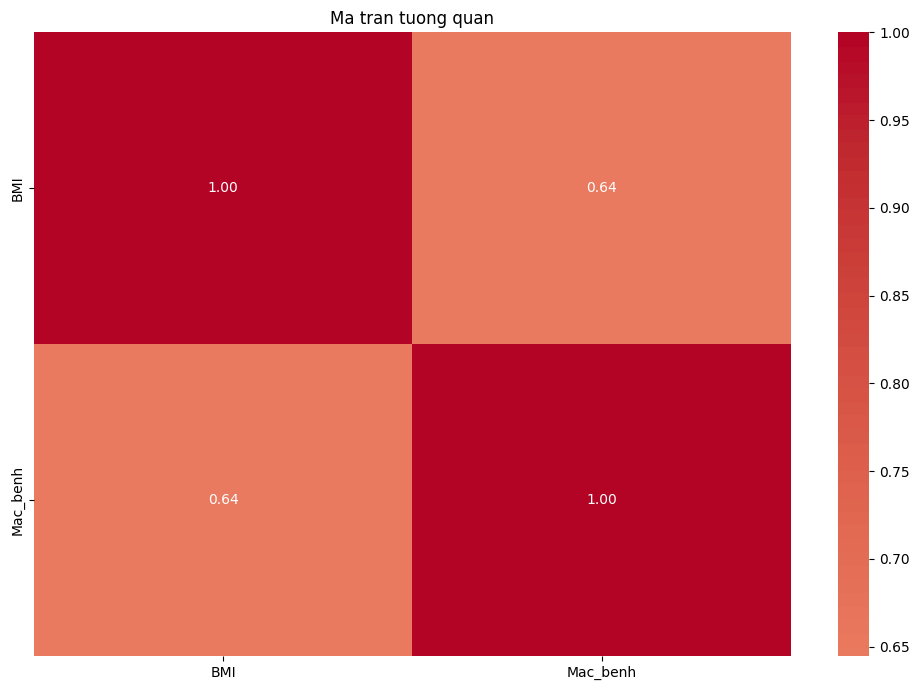


========== SO SANH MO HINH ==========


,Mo hinh,R2,MAE,MSE,RMSE
2,Random Forest,0.531051,0.182813,0.112548,0.335481
0,Hoi quy tuyen tinh,0.479796,0.287120,0.124849,0.353340
1,Ridge,0.479178,0.287592,0.124997,0.353549


Mo hinh duoc chon: Random Forest


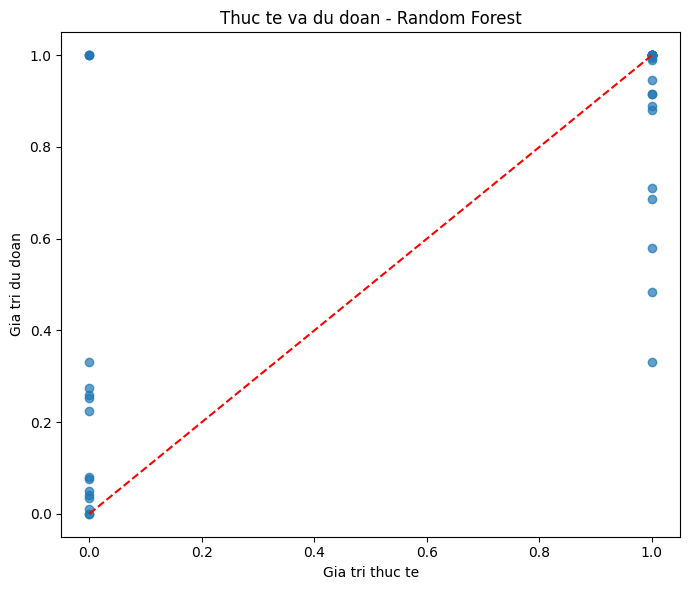

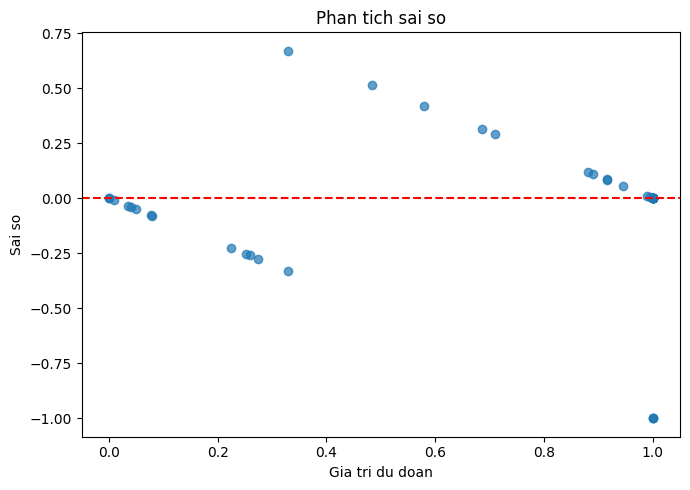

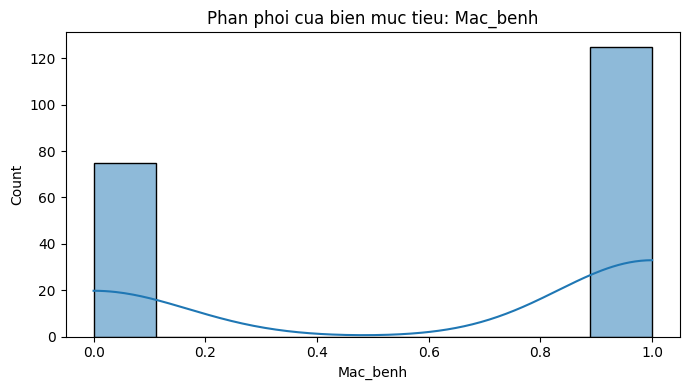


========== NHAN XET ==========
Bien can du doan: Mac_benh
Mo hinh tot nhat trong cac mo hinh da thu: Random Forest
R2   = 0.5311
MAE  = 0.1828
MSE  = 0.1125
RMSE = 0.3355
R2 o muc vua phai, co the can them du lieu hoac bien dau vao.
Luu y: Ket qua phu thuoc chat luong va kich thuoc du lieu.
Tuong quan khong dong nghia voi quan he nhan qua.

DA HOAN THANH! Dang tai cac file ket qua...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:


!pip -q install chardet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import chardet

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error,
    mean_squared_error
)


print("Hay chon file CSV de phan tich:")
uploaded = files.upload()

filename = next(iter(uploaded))
raw = uploaded[filename]

encoding = chardet.detect(raw[:100000]).get("encoding") or "utf-8"
content = raw.decode(encoding, errors="replace")

try:
    import csv
    delimiter = csv.Sniffer().sniff(
        content[:10000], delimiters=",;\t|"
    ).delimiter
except:
    delimiter = ","

df = pd.read_csv(io.StringIO(content), sep=delimiter)
df.columns = df.columns.astype(str).str.strip()
df = df.dropna(how="all").dropna(axis=1, how="all")


for col in df.select_dtypes(include="object").columns:
    s = df[col].astype(str).str.strip()
    converted = pd.to_numeric(
        s.str.replace(",", ".", regex=False),
        errors="coerce"
    )
    valid = s.isin(["", "nan", "None"]) == False
    if valid.sum() and converted[valid].notna().mean() >= 0.85:
        df[col] = converted

print("\n========== TONG QUAN DU LIEU ==========")
print("So dong:", df.shape[0])
print("So cot:", df.shape[1])
display(df.head())
display(df.describe(include="all").T)

print("\nGia tri thieu theo cot:")
display(df.isnull().sum().to_frame("So gia tri thieu"))


numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if len(numeric_cols) < 2:
    raise ValueError(
        "Can it nhat 2 cot so: mot cot muc tieu Y "
        "va mot cot dau vao X."
    )


keywords = [
    "target", "label", "price", "gia", "score", "diem",
    "sales", "revenue", "doanh thu", "salary", "luong",
    "profit", "total", "tong", "outcome", "ket qua"
]

def target_score(col):
    name = str(col).lower()
    score = sum(k in name for k in keywords) * 3
    if name.strip() in ["y", "target", "label", "outcome"]:
        score += 10
    return score

eligible = [
    c for c in numeric_cols
    if df[c].notna().sum() >= max(5, int(len(df) * 0.5))
    and df[c].nunique() > 1
]

if len(eligible) < 2:
    raise ValueError(
        "Khong tim duoc du cot so hop le de hoi quy."
    )


target = max(
    eligible,
    key=lambda c: (target_score(c), df.columns.get_loc(c))
)

print("\n========== BIEN MUC TIEU ==========")
print("Chuong trinh tu chon Y =", target)
print("Luu y: Hay kiem tra Y co dung muc tieu ban muon du doan.")


features = []
for col in df.columns:
    if col == target or df[col].nunique(dropna=True) <= 1:
        continue

    name = str(col).lower()
    unique_ratio = (
        df[col].nunique(dropna=True)
        / max(df[col].notna().sum(), 1)
    )

    if any(k in name for k in ["id", "ma_", "code", "stt"]) and unique_ratio > 0.5:
        continue

    if df[col].notna().sum() >= max(3, int(len(df) * 0.3)):
        features.append(col)

if not features:
    raise ValueError("Khong co cot dau vao phu hop.")


X = df[features].copy()
y = pd.to_numeric(df[target], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

for col in list(X.columns):
    if X[col].dtype == "object":
        if X[col].nunique(dropna=True) > min(100, max(30, len(X) // 2)):
            X.drop(columns=col, inplace=True)

if X.shape[1] == 0 or len(X) < 5:
    raise ValueError("Du lieu sau lam sach khong du de hoi quy.")

print("Cac bien X:", X.columns.tolist())
print("So dong duoc su dung:", len(X))


numeric_data = df.select_dtypes(include=np.number)

if numeric_data.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        numeric_data.corr(),
        annot=True, cmap="coolwarm",
        fmt=".2f", center=0
    )
    plt.title("Ma tran tuong quan")
    plt.tight_layout()
    plt.show()


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2 if len(X) >= 10 else 0.4,
    random_state=42
)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

transformers = []

if num_cols:
    transformers.append((
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        num_cols
    ))

if cat_cols:
    transformers.append((
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        cat_cols
    ))

preprocessor = ColumnTransformer(transformers)


models = {
    "Hoi quy tuyen tinh": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

results = []
trained = {}
predictions = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    try:
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)

        mse = mean_squared_error(y_test, pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, pred) if len(y_test) >= 2 else np.nan
        mae = mean_absolute_error(y_test, pred)

        results.append({
            "Mo hinh": name,
            "R2": r2,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse
        })

        trained[name] = pipe
        predictions[name] = pred

    except Exception as e:
        print("Loi mo hinh", name, ":", e)

if not results:
    raise ValueError("Tat ca mo hinh deu that bai.")

metrics = pd.DataFrame(results)


if metrics["R2"].notna().any():
    best_name = metrics.sort_values(
        ["R2", "RMSE"], ascending=[False, True]
    ).iloc[0]["Mo hinh"]
else:
    best_name = metrics.sort_values("RMSE").iloc[0]["Mo hinh"]

best_model = trained[best_name]
best_pred = predictions[best_name]

print("\n========== SO SANH MO HINH ==========")
display(metrics.sort_values("RMSE"))
print("Mo hinh duoc chon:", best_name)


plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.7)

low = min(y_test.min(), np.min(best_pred))
high = max(y_test.max(), np.max(best_pred))
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Gia tri thuc te")
plt.ylabel("Gia tri du doan")
plt.title("Thuc te va du doan - " + best_name)
plt.tight_layout()
plt.show()


residuals = np.asarray(y_test) - np.asarray(best_pred)

plt.figure(figsize=(7, 5))
plt.scatter(best_pred, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Gia tri du doan")
plt.ylabel("Sai so")
plt.title("Phan tich sai so")
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 4))
sns.histplot(y, kde=True)
plt.title("Phan phoi cua bien muc tieu: " + str(target))
plt.tight_layout()
plt.show()


row = metrics[metrics["Mo hinh"] == best_name].iloc[0]

print("\n========== NHAN XET ==========")
print("Bien can du doan:", target)
print("Mo hinh tot nhat trong cac mo hinh da thu:", best_name)
print(f"R2   = {row['R2']:.4f}")
print(f"MAE  = {row['MAE']:.4f}")
print(f"MSE  = {row['MSE']:.4f}")
print(f"RMSE = {row['RMSE']:.4f}")

if pd.notna(row["R2"]):
    if row["R2"] >= 0.7:
        print("R2 tuong doi cao tren tap kiem tra.")
    elif row["R2"] >= 0.3:
        print("R2 o muc vua phai, co the can them du lieu hoac bien dau vao.")
    elif row["R2"] >= 0:
        print("R2 thap, kha nang du doan con han che.")
    else:
        print("R2 am: mo hinh kem hon viec du doan bang gia tri trung binh.")

print("Luu y: Ket qua phu thuoc chat luong va kich thuoc du lieu.")
print("Tuong quan khong dong nghia voi quan he nhan qua.")


all_X = df.reindex(columns=X.columns).copy()

for col in all_X.columns:
    if col in num_cols:
        all_X[col] = pd.to_numeric(all_X[col], errors="coerce")

all_predictions = best_model.predict(all_X)

output = df.copy()
output["Du_doan_" + str(target)] = all_predictions
output["Sai_so"] = (
    pd.to_numeric(output[target], errors="coerce")
    - output["Du_doan_" + str(target)]
)


test_output = X_test.copy()
test_output["Gia_tri_thuc_te"] = y_test
test_output["Gia_tri_du_doan"] = best_pred
test_output["Sai_so"] = np.asarray(y_test) - np.asarray(best_pred)

metrics.to_csv(
    "so_sanh_mo_hinh.csv", index=False, encoding="utf-8-sig"
)
output.to_csv(
    "du_doan_toan_bo_du_lieu.csv", index=False, encoding="utf-8-sig"
)
test_output.to_csv(
    "ket_qua_tap_kiem_tra.csv", index=True, encoding="utf-8-sig"
)

summary = pd.DataFrame({
    "Thong tin": [
        "File dau vao", "So dong", "So cot",
        "Bien muc tieu Y", "Bien dau vao X",
        "Mo hinh duoc chon", "R2", "MAE", "MSE", "RMSE"
    ],
    "Gia tri": [
        filename, len(df), df.shape[1],
        target, ", ".join(X.columns.astype(str)),
        best_name, row["R2"], row["MAE"], row["MSE"], row["RMSE"]
    ]
})
summary.to_csv(
    "bao_cao_tong_hop.csv", index=False, encoding="utf-8-sig"
)

print("\nDA HOAN THANH! Dang tai cac file ket qua...")
files.download("bao_cao_tong_hop.csv")
files.download("so_sanh_mo_hinh.csv")
files.download("du_doan_toan_bo_du_lieu.csv")
files.download("ket_qua_tap_kiem_tra.csv")


Hay chon file CSV de phan tich:


Saving du_lieu_bai3_tieu_duong.csv to du_lieu_bai3_tieu_duong.csv

========== TONG QUAN DU LIEU ==========
So dong: 200
So cot: 5


,Tuoi,BMI,Duong_huyet_mg_dL,Huyet_ap_mmHg,Nguco_tieu_duong
0,60,25.0,147.2,116.3,0
1,49,38.8,119.5,70.9,0
2,36,33.6,196.1,64.0,1
3,68,30.4,179.5,104.5,1
4,39,19.7,179.0,94.5,1


,count,mean,std,min,25%,50%,75%,max
Tuoi,200.0,47.0700,15.920187,20.0,32.75,47.00,61.000,74.0
BMI,200.0,27.6155,7.078974,16.1,21.50,27.90,34.150,39.7
Duong_huyet_mg_dL,200.0,131.2255,36.763882,71.9,99.20,129.80,158.900,200.0
Huyet_ap_mmHg,200.0,89.0860,17.099229,60.3,73.45,87.75,104.225,119.8
Nguco_tieu_duong,200.0,0.4500,0.498742,0.0,0.00,0.00,1.000,1.0



Gia tri thieu theo cot:


,So gia tri thieu
Tuoi,0
BMI,0
Duong_huyet_mg_dL,0
Huyet_ap_mmHg,0
Nguco_tieu_duong,0



========== BIEN MUC TIEU ==========
Chuong trinh tu chon Y = Nguco_tieu_duong
Luu y: Hay kiem tra Y co dung muc tieu ban muon du doan.
Cac bien X: ['Tuoi', 'BMI', 'Duong_huyet_mg_dL', 'Huyet_ap_mmHg']
So dong duoc su dung: 200


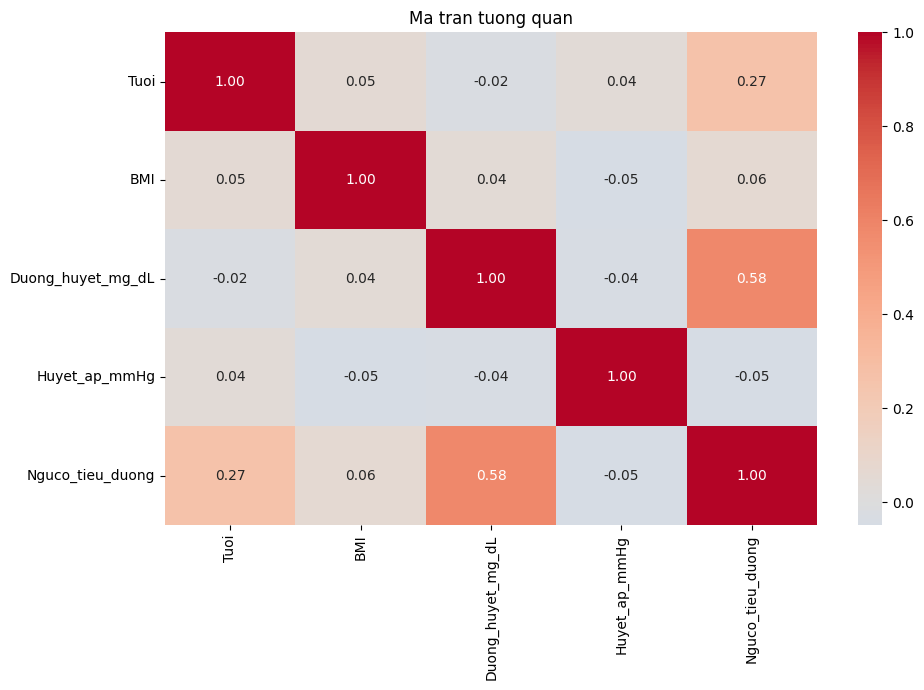


========== SO SANH MO HINH ==========


,Mo hinh,R2,MAE,MSE,RMSE
2,Random Forest,0.335508,0.282375,0.164462,0.405539
1,Ridge,0.320789,0.320784,0.168105,0.410006
0,Hoi quy tuyen tinh,0.319772,0.320409,0.168356,0.410313


Mo hinh duoc chon: Random Forest


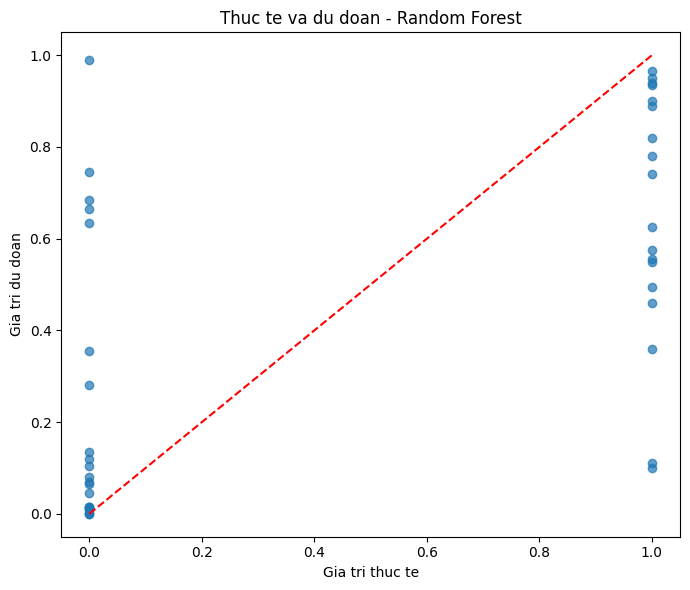

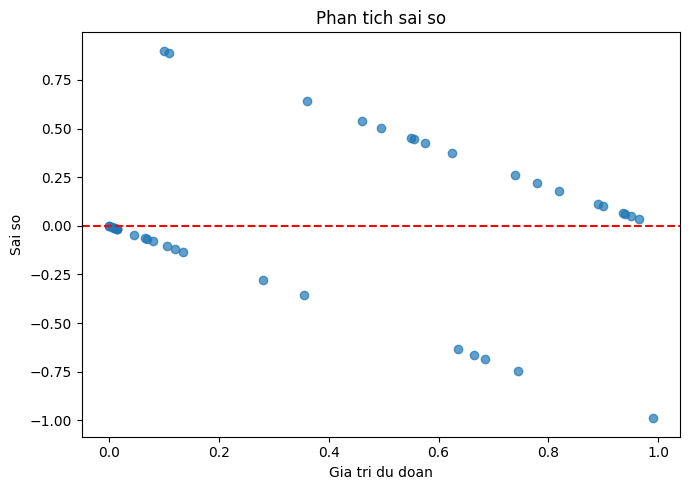

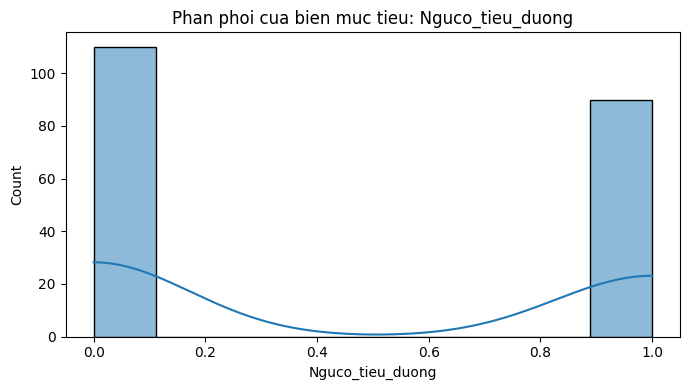


========== NHAN XET ==========
Bien can du doan: Nguco_tieu_duong
Mo hinh tot nhat trong cac mo hinh da thu: Random Forest
R2   = 0.3355
MAE  = 0.2824
MSE  = 0.1645
RMSE = 0.4055
R2 o muc vua phai, co the can them du lieu hoac bien dau vao.
Luu y: Ket qua phu thuoc chat luong va kich thuoc du lieu.
Tuong quan khong dong nghia voi quan he nhan qua.

DA HOAN THANH! Dang tai cac file ket qua...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:


!pip -q install chardet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import chardet

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error,
    mean_squared_error
)


print("Hay chon file CSV de phan tich:")
uploaded = files.upload()

filename = next(iter(uploaded))
raw = uploaded[filename]

encoding = chardet.detect(raw[:100000]).get("encoding") or "utf-8"
content = raw.decode(encoding, errors="replace")

try:
    import csv
    delimiter = csv.Sniffer().sniff(
        content[:10000], delimiters=",;\t|"
    ).delimiter
except:
    delimiter = ","

df = pd.read_csv(io.StringIO(content), sep=delimiter)
df.columns = df.columns.astype(str).str.strip()
df = df.dropna(how="all").dropna(axis=1, how="all")


for col in df.select_dtypes(include="object").columns:
    s = df[col].astype(str).str.strip()
    converted = pd.to_numeric(
        s.str.replace(",", ".", regex=False),
        errors="coerce"
    )
    valid = s.isin(["", "nan", "None"]) == False
    if valid.sum() and converted[valid].notna().mean() >= 0.85:
        df[col] = converted

print("\n========== TONG QUAN DU LIEU ==========")
print("So dong:", df.shape[0])
print("So cot:", df.shape[1])
display(df.head())
display(df.describe(include="all").T)

print("\nGia tri thieu theo cot:")
display(df.isnull().sum().to_frame("So gia tri thieu"))


numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if len(numeric_cols) < 2:
    raise ValueError(
        "Can it nhat 2 cot so: mot cot muc tieu Y "
        "va mot cot dau vao X."
    )


keywords = [
    "target", "label", "price", "gia", "score", "diem",
    "sales", "revenue", "doanh thu", "salary", "luong",
    "profit", "total", "tong", "outcome", "ket qua"
]

def target_score(col):
    name = str(col).lower()
    score = sum(k in name for k in keywords) * 3
    if name.strip() in ["y", "target", "label", "outcome"]:
        score += 10
    return score

eligible = [
    c for c in numeric_cols
    if df[c].notna().sum() >= max(5, int(len(df) * 0.5))
    and df[c].nunique() > 1
]

if len(eligible) < 2:
    raise ValueError(
        "Khong tim duoc du cot so hop le de hoi quy."
    )


target = max(
    eligible,
    key=lambda c: (target_score(c), df.columns.get_loc(c))
)

print("\n========== BIEN MUC TIEU ==========")
print("Chuong trinh tu chon Y =", target)
print("Luu y: Hay kiem tra Y co dung muc tieu ban muon du doan.")


features = []
for col in df.columns:
    if col == target or df[col].nunique(dropna=True) <= 1:
        continue

    name = str(col).lower()
    unique_ratio = (
        df[col].nunique(dropna=True)
        / max(df[col].notna().sum(), 1)
    )

    if any(k in name for k in ["id", "ma_", "code", "stt"]) and unique_ratio > 0.5:
        continue

    if df[col].notna().sum() >= max(3, int(len(df) * 0.3)):
        features.append(col)

if not features:
    raise ValueError("Khong co cot dau vao phu hop.")


X = df[features].copy()
y = pd.to_numeric(df[target], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

for col in list(X.columns):
    if X[col].dtype == "object":
        if X[col].nunique(dropna=True) > min(100, max(30, len(X) // 2)):
            X.drop(columns=col, inplace=True)

if X.shape[1] == 0 or len(X) < 5:
    raise ValueError("Du lieu sau lam sach khong du de hoi quy.")

print("Cac bien X:", X.columns.tolist())
print("So dong duoc su dung:", len(X))


numeric_data = df.select_dtypes(include=np.number)

if numeric_data.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        numeric_data.corr(),
        annot=True, cmap="coolwarm",
        fmt=".2f", center=0
    )
    plt.title("Ma tran tuong quan")
    plt.tight_layout()
    plt.show()


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2 if len(X) >= 10 else 0.4,
    random_state=42
)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in X.columns if c not in num_cols]

transformers = []

if num_cols:
    transformers.append((
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        num_cols
    ))

if cat_cols:
    transformers.append((
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        cat_cols
    ))

preprocessor = ColumnTransformer(transformers)


models = {
    "Hoi quy tuyen tinh": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42
    )
}

results = []
trained = {}
predictions = {}

for name, model in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    try:
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)

        mse = mean_squared_error(y_test, pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, pred) if len(y_test) >= 2 else np.nan
        mae = mean_absolute_error(y_test, pred)

        results.append({
            "Mo hinh": name,
            "R2": r2,
            "MAE": mae,
            "MSE": mse,
            "RMSE": rmse
        })

        trained[name] = pipe
        predictions[name] = pred

    except Exception as e:
        print("Loi mo hinh", name, ":", e)

if not results:
    raise ValueError("Tat ca mo hinh deu that bai.")

metrics = pd.DataFrame(results)


if metrics["R2"].notna().any():
    best_name = metrics.sort_values(
        ["R2", "RMSE"], ascending=[False, True]
    ).iloc[0]["Mo hinh"]
else:
    best_name = metrics.sort_values("RMSE").iloc[0]["Mo hinh"]

best_model = trained[best_name]
best_pred = predictions[best_name]

print("\n========== SO SANH MO HINH ==========")
display(metrics.sort_values("RMSE"))
print("Mo hinh duoc chon:", best_name)


plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.7)

low = min(y_test.min(), np.min(best_pred))
high = max(y_test.max(), np.max(best_pred))
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Gia tri thuc te")
plt.ylabel("Gia tri du doan")
plt.title("Thuc te va du doan - " + best_name)
plt.tight_layout()
plt.show()


residuals = np.asarray(y_test) - np.asarray(best_pred)

plt.figure(figsize=(7, 5))
plt.scatter(best_pred, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Gia tri du doan")
plt.ylabel("Sai so")
plt.title("Phan tich sai so")
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 4))
sns.histplot(y, kde=True)
plt.title("Phan phoi cua bien muc tieu: " + str(target))
plt.tight_layout()
plt.show()


row = metrics[metrics["Mo hinh"] == best_name].iloc[0]

print("\n========== NHAN XET ==========")
print("Bien can du doan:", target)
print("Mo hinh tot nhat trong cac mo hinh da thu:", best_name)
print(f"R2   = {row['R2']:.4f}")
print(f"MAE  = {row['MAE']:.4f}")
print(f"MSE  = {row['MSE']:.4f}")
print(f"RMSE = {row['RMSE']:.4f}")

if pd.notna(row["R2"]):
    if row["R2"] >= 0.7:
        print("R2 tuong doi cao tren tap kiem tra.")
    elif row["R2"] >= 0.3:
        print("R2 o muc vua phai, co the can them du lieu hoac bien dau vao.")
    elif row["R2"] >= 0:
        print("R2 thap, kha nang du doan con han che.")
    else:
        print("R2 am: mo hinh kem hon viec du doan bang gia tri trung binh.")

print("Luu y: Ket qua phu thuoc chat luong va kich thuoc du lieu.")
print("Tuong quan khong dong nghia voi quan he nhan qua.")


all_X = df.reindex(columns=X.columns).copy()

for col in all_X.columns:
    if col in num_cols:
        all_X[col] = pd.to_numeric(all_X[col], errors="coerce")

all_predictions = best_model.predict(all_X)

output = df.copy()
output["Du_doan_" + str(target)] = all_predictions
output["Sai_so"] = (
    pd.to_numeric(output[target], errors="coerce")
    - output["Du_doan_" + str(target)]
)


test_output = X_test.copy()
test_output["Gia_tri_thuc_te"] = y_test
test_output["Gia_tri_du_doan"] = best_pred
test_output["Sai_so"] = np.asarray(y_test) - np.asarray(best_pred)

metrics.to_csv(
    "so_sanh_mo_hinh.csv", index=False, encoding="utf-8-sig"
)
output.to_csv(
    "du_doan_toan_bo_du_lieu.csv", index=False, encoding="utf-8-sig"
)
test_output.to_csv(
    "ket_qua_tap_kiem_tra.csv", index=True, encoding="utf-8-sig"
)

summary = pd.DataFrame({
    "Thong tin": [
        "File dau vao", "So dong", "So cot",
        "Bien muc tieu Y", "Bien dau vao X",
        "Mo hinh duoc chon", "R2", "MAE", "MSE", "RMSE"
    ],
    "Gia tri": [
        filename, len(df), df.shape[1],
        target, ", ".join(X.columns.astype(str)),
        best_name, row["R2"], row["MAE"], row["MSE"], row["RMSE"]
    ]
})
summary.to_csv(
    "bao_cao_tong_hop.csv", index=False, encoding="utf-8-sig"
)

print("\nDA HOAN THANH! Dang tai cac file ket qua...")
files.download("bao_cao_tong_hop.csv")
files.download("so_sanh_mo_hinh.csv")
files.download("du_doan_toan_bo_du_lieu.csv")
files.download("ket_qua_tap_kiem_tra.csv")
